# Titanic Survival Prediction using Machine Learning
**Mini Project - Machine Learning**

## 1. Problem Statement
The Titanic ship sank in 1912 and many passengers died. In this project we use **machine learning to predict whether a
passenger survived or not**, using details like gender, age, ticket class and fare.

## 2. Type of Machine Learning: Supervised Learning
- **Supervised learning** = we train the model on data where the **correct answer is already known**.
- Here the correct answer is the column `Survived` (1 = survived, 0 = died). This column is called the **target / label**.
- The other columns (Sex, Age, Pclass ...) are called **features**.
- The model learns the pattern between features and the target, then predicts for new passengers.
- Because the answer is one of two classes (0 or 1), this is **Classification** (a type of supervised learning).

**Steps we follow:** Load data -> Clean data -> Explore (graphs) -> Split into train/test -> Train models -> Compare -> Predict

## 3. Import Libraries

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

## 4. Load the Dataset

In [2]:
df = pd.read_csv("titanic_raw.csv")
print("Rows, Columns:", df.shape)
df.head()

Rows, Columns: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


**Columns:** Survived (target), Pclass (ticket class 1/2/3), Name, Sex, Age, SibSp (siblings/spouse aboard),
Parch (parents/children aboard), Ticket, Fare (ticket price), Cabin, Embarked (port: S/C/Q).

## 5. Data Cleaning

### Step 1: Check missing values

In [3]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

- **Age** has 177 missing values -> fill with the **median age**.
- **Embarked** has 2 missing -> fill with the **most common port**.
- **Cabin** has 687 missing (too many) -> **drop** this column.
- **PassengerId, Name, Ticket** are just identifiers and do not help prediction -> **drop**.

In [4]:
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
df = df.drop(columns=["Cabin"])

print("Missing values left:", df.isnull().sum().sum())

Missing values left: 0


### Step 2: Convert text to numbers
Machine learning models understand only numbers, so we convert:
- Sex: male = 0, female = 1
- Embarked: S = 0, C = 1, Q = 2

In [5]:
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})
df["Embarked"] = df["Embarked"].map({"S": 0, "C": 1, "Q": 2})

# Save the cleaned data
clean = df.drop(columns=["PassengerId", "Name", "Ticket"])
clean.to_csv("titanic_analysis.csv", index=False)
clean.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,0,22.0,1,0,7.2500,0
1,1,1,1,38.0,1,0,71.2833,1
2,1,3,1,26.0,0,0,7.9250,0
3,1,1,1,35.0,1,0,53.1000,0
4,0,3,0,35.0,0,0,8.0500,0


## 6. Exploratory Data Analysis (Graphs)

/tmp/ipykernel_85/2818712789.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="Survived", palette=["#D9534F", "#4C9F70"])


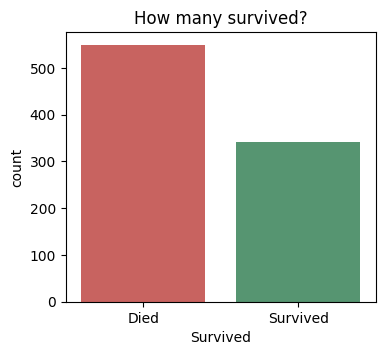

Survived
0    62.0
1    38.0
Name: proportion, dtype: float64


In [6]:
plt.figure(figsize=(4, 3.5))
sns.countplot(data=df, x="Survived", palette=["#D9534F", "#4C9F70"])
plt.xticks([0, 1], ["Died", "Survived"])
plt.title("How many survived?")
plt.show()
print(df["Survived"].value_counts(normalize=True).round(2) * 100)

/tmp/ipykernel_85/3016401949.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="Sex", y="Survived", ax=ax[0], palette="Set2")
/tmp/ipykernel_85/3016401949.py:3: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[0].set_xticklabels(["Male", "Female"]); ax[0].set_title("Survival rate by Gender")
/tmp/ipykernel_85/3016401949.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="Pclass", y="Survived", ax=ax[1], palette="Set2")


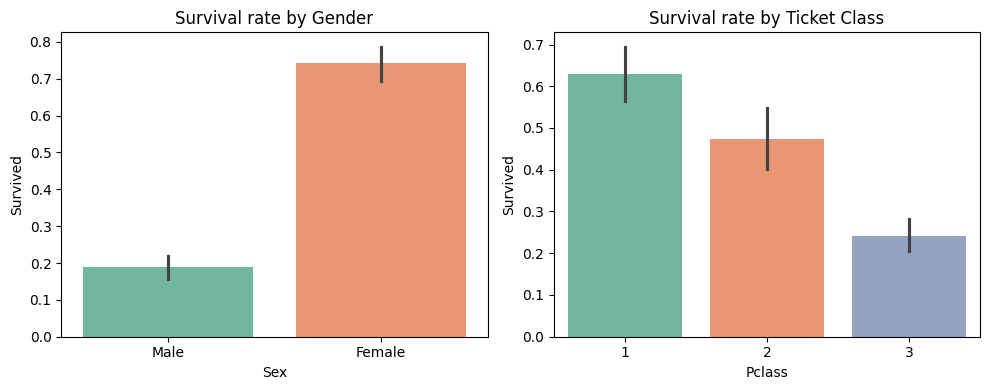

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.barplot(data=df, x="Sex", y="Survived", ax=ax[0], palette="Set2")
ax[0].set_xticklabels(["Male", "Female"]); ax[0].set_title("Survival rate by Gender")
sns.barplot(data=df, x="Pclass", y="Survived", ax=ax[1], palette="Set2")
ax[1].set_title("Survival rate by Ticket Class")
plt.tight_layout(); plt.show()

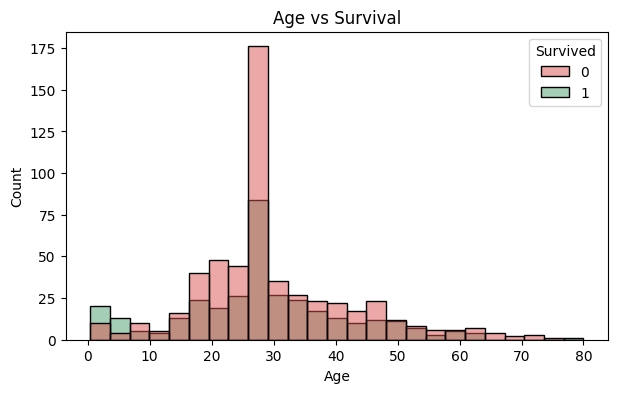

In [8]:
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="Age", hue="Survived", bins=25, palette=["#D9534F", "#4C9F70"])
plt.title("Age vs Survival")
plt.show()

**What the graphs tell us**
- Only about **38%** of passengers survived.
- **Women survived much more than men** (about 74% vs 19%).
- **First class** passengers survived more than third class.
- **Children** had a better chance of survival.

## 7. Split Data into Train and Test
- **X** = features (inputs), **y** = target (answer).
- **80% training data**: the model learns from this.
- **20% testing data**: the model has never seen this; we use it to check how good the model is.

In [9]:
X = df[["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]]
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training rows:", len(X_train), "| Testing rows:", len(X_test))

Training rows: 712 | Testing rows: 179


## 8. Train the Models (all Supervised Classification algorithms)
| Model | Simple idea |
|---|---|
| **Logistic Regression** | Draws a boundary line between survived and died using a mathematical formula |
| **Random Forest** | Many decision trees vote together; the majority answer wins |

In [10]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
}

rows = []
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)          # learn from training data
    pred = model.predict(X_test)         # predict on unseen test data
    predictions[name] = pred
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1-Score": f1_score(y_test, pred),
    })

results = pd.DataFrame(rows).round(4).sort_values("Accuracy", ascending=False).reset_index(drop=True)
results.to_csv("model_comparison.csv", index=False)
results

,Model,Accuracy,Precision,Recall,F1-Score
0,Random Forest,0.8268,0.8116,0.7568,0.7832
1,Logistic Regression,0.7989,0.7714,0.7297,0.7500


**Metrics in simple words**
- **Accuracy**: out of all passengers, how many did the model predict correctly?
- **Precision**: when the model says "survived", how often is it right?
- **Recall**: out of all who really survived, how many did the model find?
- **F1-Score**: one number that balances precision and recall.

/tmp/ipykernel_85/1628797658.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=results, x="Accuracy", y="Model", palette="Blues_r")


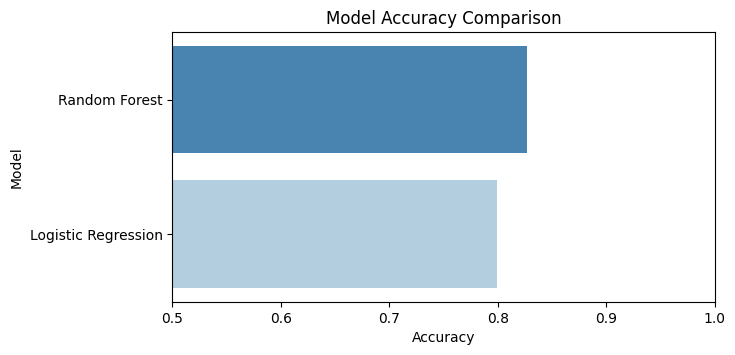

In [11]:
plt.figure(figsize=(7, 3.5))
sns.barplot(data=results, x="Accuracy", y="Model", palette="Blues_r")
plt.xlim(0.5, 1); plt.title("Model Accuracy Comparison")
plt.show()

## 9. Best Model and Confusion Matrix

Best model: Random Forest | Accuracy: 0.8268


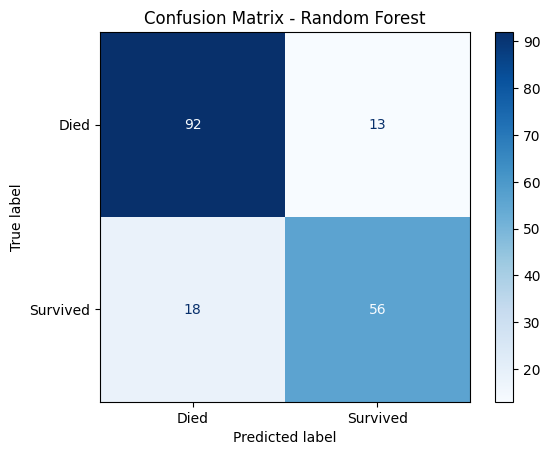

In [12]:
best_name = results.loc[0, "Model"]
best_model = models[best_name]
print("Best model:", best_name, "| Accuracy:", results.loc[0, "Accuracy"])

ConfusionMatrixDisplay.from_predictions(y_test, predictions[best_name],
                                        display_labels=["Died", "Survived"], cmap="Blues")
plt.title("Confusion Matrix - " + best_name)
plt.show()

**How to read the confusion matrix:** top-left and bottom-right are the **correct** predictions;
the other two boxes are the **mistakes**.

## 10. Which features matter most? (Random Forest)

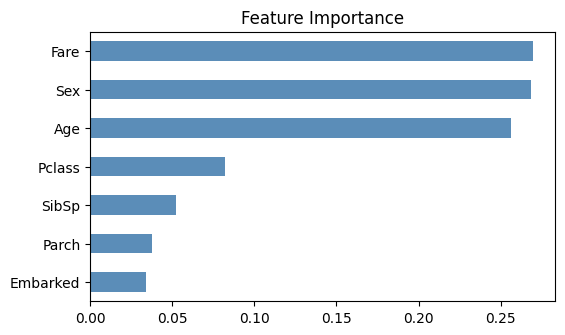

In [13]:
imp = pd.Series(models["Random Forest"].feature_importances_, index=X.columns).sort_values()
imp.plot(kind="barh", color="#5B8DB8", figsize=(6, 3.5), title="Feature Importance")
plt.show()

## 11. Save Predictions

In [14]:
out = df.loc[X_test.index, ["PassengerId", "Name"]].copy()
out["Actual"] = y_test.map({0: "Died", 1: "Survived"})
out["Predicted"] = pd.Series(predictions[best_name], index=X_test.index).map({0: "Died", 1: "Survived"})
out["Correct"] = (out["Actual"] == out["Predicted"]).map({True: "Yes", False: "No"})
out = out.sort_values("PassengerId").reset_index(drop=True)
out.to_csv("survival_predictions.csv", index=False)
print("Correct predictions:", (out["Correct"] == "Yes").sum(), "out of", len(out))
out.head(10)

Correct predictions: 148 out of 179


,PassengerId,Name,Actual,Predicted,Correct
0,6,"Moran, Mr. James",Died,Died,Yes
1,11,"Sandstrom, Miss. Marguerite Rut",Survived,Survived,Yes
2,24,"Sloper, Mr. William Thompson",Survived,Survived,Yes
3,26,"Asplund, Mrs. Carl Oscar (Selma Augusta Emilia...",Survived,Died,No
4,31,"Uruchurtu, Don. Manuel E",Died,Died,Yes
5,32,"Spencer, Mrs. William Augustus (Marie Eugenie)",Survived,Survived,Yes
6,34,"Wheadon, Mr. Edward H",Died,Survived,No
7,40,"Nicola-Yarred, Miss. Jamila",Survived,Died,No
8,45,"Devaney, Miss. Margaret Delia",Survived,Died,No
9,50,"Arnold-Franchi, Mrs. Josef (Josefine Franchi)",Died,Died,Yes


## 12. Predict for a New Passenger

In [15]:
def predict_passenger(pclass, sex, age, sibsp, parch, fare, embarked):
    # sex: "male"/"female" | embarked: "S"/"C"/"Q"
    row = pd.DataFrame([[pclass, 0 if sex == "male" else 1, age, sibsp, parch, fare,
                         {"S": 0, "C": 1, "Q": 2}[embarked]]], columns=X.columns)
    return "Survived" if best_model.predict(row)[0] == 1 else "Died"

print("1st class woman, age 28 :", predict_passenger(1, "female", 28, 0, 0, 80, "S"))
print("3rd class man, age 30   :", predict_passenger(3, "male", 30, 0, 0, 8, "S"))
print("2nd class girl, age 8   :", predict_passenger(2, "female", 8, 1, 1, 26, "S"))

1st class woman, age 28 : Survived
3rd class man, age 30   : Died
2nd class girl, age 8   : Survived


## 13. Conclusion
- We used **supervised learning (classification)** to predict Titanic survival from passenger details.
- Two models were trained and tested on 179 unseen passengers:
  - **Random Forest: 82.7% accuracy (best)** - 148 of 179 predictions correct
  - Logistic Regression: 79.9% accuracy
- **Gender, fare and age** were the most important features in the Random Forest. Gender had by far the strongest effect in the graphs: women survived far more than men ("women and children first"). Passenger class also mattered: first class survived more than third class.
- **Limitations:** the dataset is small (891 passengers) and only 2 models were tried with default settings.
- **Future work:** try more models (KNN, SVM), tune parameters, and add features such as family size and title from the name.